In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
faces = fetch_olivetti_faces(
    shuffle=True,
    random_state=42
)

X = faces.data
y = faces.target
images = faces.images

print("Dataset loaded successfully!")
print("Number of images:", len(images))
print("Image shape:", images[0].shape)
print("Feature shape:", X.shape)
print("Number of people:", len(np.unique(y)))

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Dataset loaded successfully!
Number of images: 400
Image shape: (64, 64)
Feature shape: (400, 4096)
Number of people: 40


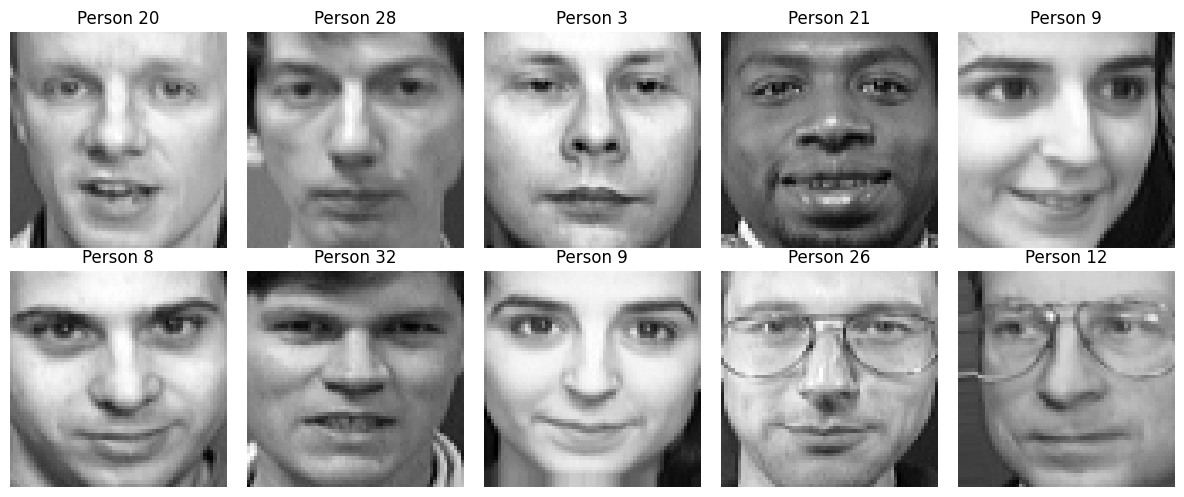

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Person {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 320
Testing samples: 80


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [6]:
pca = PCA(
    n_components=150,
    whiten=True,
    random_state=42
)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train.shape[1])
print("PCA features:", X_train_pca.shape[1])

print(
    "Explained variance:",
    round(np.sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

Original features: 4096
PCA features: 150
Explained variance: 97.06 %


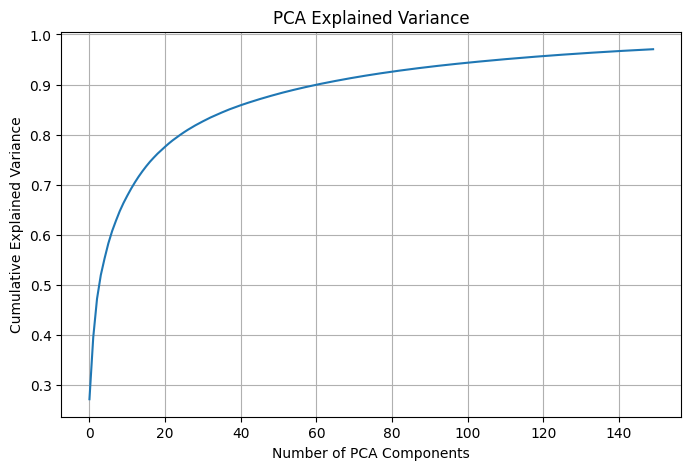

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    np.cumsum(pca.explained_variance_ratio_)
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")

plt.grid()
plt.show()

In [18]:
ann = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=1500,
    random_state=42,
    early_stopping=False
)

ann.fit(X_train_pca, y_train)

print("ANN training completed!")

ANN training completed!


In [19]:
y_pred = ann.predict(X_test_pca)

accuracy = accuracy_score(y_test, y_pred)

print("Face Recognition Accuracy:",
      round(accuracy * 100, 2),
      "%")

Face Recognition Accuracy: 91.25 %


In [10]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.00      0.00      0.00         2
           2       0.00      0.00      0.00         2
           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         2
           5       0.00      0.00      0.00         2
           6       0.00      0.00      0.00         2
           7       0.00      0.00      0.00         2
           8       0.00      0.00      0.00         2
           9       0.00      0.00      0.00         2
          10       0.00      0.00      0.00         2
          11       0.00      0.00      0.00         2
          12       0.00      0.00      0.00         2
          13       0.00      0.00      0.00         2
          14       0.00      0.00      0.00         2
          15       0.00      0.00      0.00         2
          16       0.20      0.50      0.29         2
          17       0.00    

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


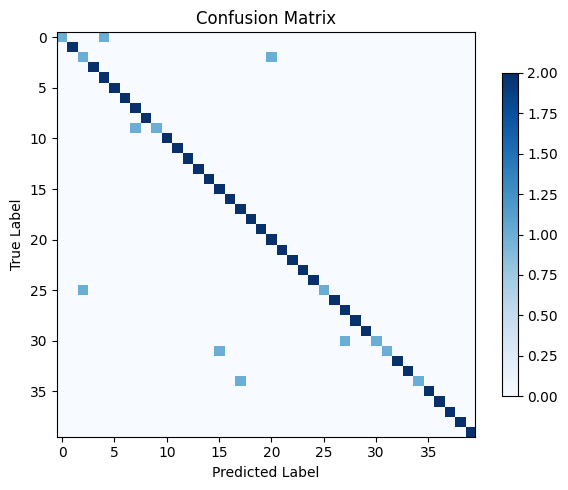

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues", aspect="auto")

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.colorbar(shrink=0.8)

plt.tight_layout()
plt.show()

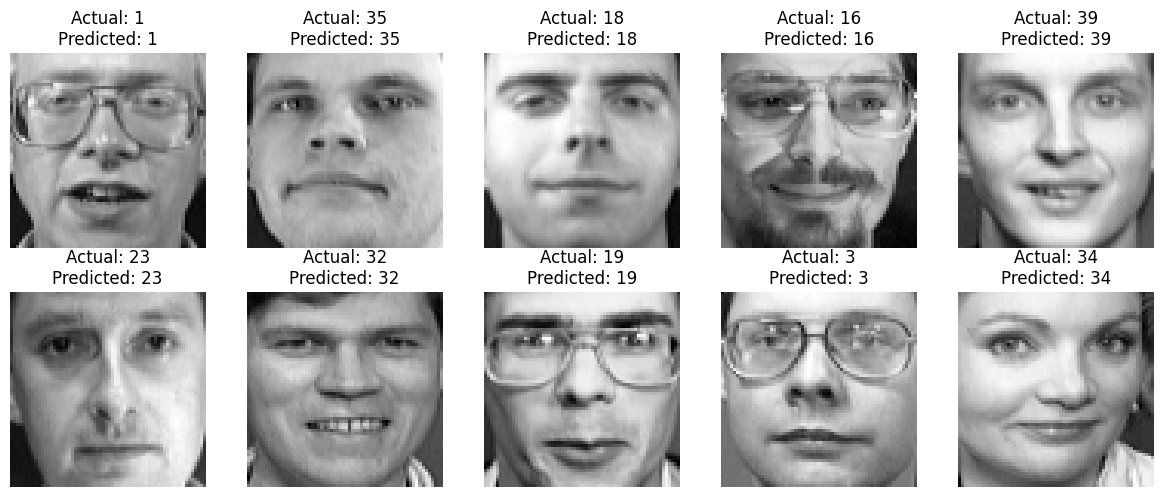

In [21]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.ravel()):

    image = X_test[i].reshape(64, 64)

    ax.imshow(image, cmap="gray")

    ax.set_title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
import joblib

joblib.dump(scaler, "scaler.pkl")
joblib.dump(pca, "pca.pkl")
joblib.dump(ann, "face_recognition_ann.pkl")

print("Models saved successfully!")

Models saved successfully!


In [23]:
def predict_face(index):

    sample = X_test[index].reshape(1, -1)

    sample_scaled = scaler.transform(sample)

    sample_pca = pca.transform(sample_scaled)

    prediction = ann.predict(sample_pca)[0]

    probability = ann.predict_proba(sample_pca).max()

    plt.imshow(X_test[index].reshape(64, 64), cmap="gray")
    plt.axis("off")

    plt.title(
        f"Predicted Person: {prediction}\n"
        f"Confidence: {probability * 100:.2f}%"
    )

    plt.show()

    return prediction

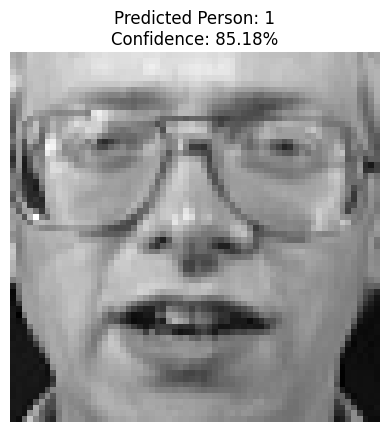

np.int64(1)

In [24]:
predict_face(0)

## Conclusion

The Face Recognition System successfully recognizes different faces using PCA and an Artificial Neural Network (ANN).

PCA reduced the original 4096 image features to 150 components, while the ANN classifier achieved a test accuracy of 91.25%.

A sample prediction correctly identified Person 1 with a confidence of 85.18%.

This project demonstrates how dimensionality reduction and neural network classification can be combined for face recognition.